[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/halla-ai/deepnlp-2026/blob/main/notebooks/week-07.ipynb)

# 7주차 실습: 장문맥 처리와 효율적 추론

**목표.** 긴 한국어 문서(위키백과 「제주특별자치도」 고정판)로 세 가지를 해 본다.

1. **문맥이 길어지면 무엇이 비싸지는가**: 모델 설정에서 KV 캐시 크기를 계산하고, 프리필(입력 읽기)과 디코딩(한 토큰씩 쓰기) 시간을 직접 잰다
2. **위치 인코딩이 길이를 정하는 방식**: RoPE의 차원 쌍별 회전 주기를 계산해 학습 길이 밖이 왜 문제인지 본다
3. **위치별 정보 회수율**: 문서 곳곳에 가상의 문장을 숨기고 모델이 찾아내는지 잰다. **문서 길이를 바꿔 가며** 길이-정확도 곡선을 그린다

GPU는 필요 없다. 노트북이 실행 시점에 문서와 모델을 내려받는다. 문서는 위키백과 본문(CC BY-SA 4.0)이고, 숨기는 문장(안내센터 출입 번호)은 실험용으로 지어낸 것이다.

## 0. 준비

아래 셀을 실행해 필요한 라이브러리를 설치한다. GPU는 필요 없다.

In [1]:
# 필요한 것 설치 (Colab에서 한 번만)
!pip -q install -U transformers
!pip -q install torch matplotlib

## 1. 먼저 그냥 실행해 보기

아래 셀들을 위에서부터 차례로 실행하세요. 아무것도 고치지 않아도 끝까지 돌아갑니다.

### 1-1. 문서 불러오기 - 위키백과 고정판

위키백과 「제주특별자치도」 문서의 **2026-09-11 판(판 번호 42464087)** 을 내려받는다. 판 번호를 고정했으므로 누가 언제 실행해도 본문은 사실상 같은 글이다(위키백과의 틀이 바뀌면 글자 수가 조금 달라질 수 있다). 표, 각주, 목차는 버리고 본문 문단만 쓴다.

In [2]:
import re, html, json, urllib.request, urllib.parse

OLDID = 42464087  # 위키백과 「제주특별자치도」 2026-09-11 판 (고정)
url = "https://ko.wikipedia.org/w/api.php?" + urllib.parse.urlencode(
    {"action": "parse", "oldid": OLDID, "prop": "text", "format": "json", "formatversion": 2})
req = urllib.request.Request(url, headers={"User-Agent": "deepnlp-course/1.0 (yj.lee@chu.ac.kr)"})
raw = json.load(urllib.request.urlopen(req, timeout=60))["parse"]["text"]

def clean(p):
    p = re.sub(r"<sup.*?</sup>", "", p, flags=re.S)  # 각주 번호 제거
    p = re.sub(r"<[^>]+>", "", p)                     # 태그 제거
    return re.sub(r"\s+", " ", html.unescape(p)).strip()

paras = [clean(p) for p in re.findall(r"<p>(.*?)</p>", raw, flags=re.S)]
paras = [p for p in paras if len(p) > 40]
# 문장 단위로 자른다. 숨길 문장을 문장 사이에 끼우기 위해서다
sents = [s.strip() for p in paras for s in re.split(r"(?<=[.다])\s+", p) if s.strip()]
n_chars = sum(len(p) for p in paras)
print(f"문단 {len(paras)}개, 문장 {len(sents)}개, {n_chars:,}자")
print("첫 문장:", sents[0][:80], "...")

문단 58개, 문장 160개, 10,556자
첫 문장: 제주특별자치도(濟州特別自治道, 제주어: 제주특벨ᄌᆞ치도, 영어: Jeju Special Self-Governing Province)는 대한민국의 ...


### 1-2. 모델 불러오기와 설정 읽기

4~6주차와 같은 Qwen3-0.6B-Base를 쓴다. 장문맥과 관련된 설정값(층 수, 헤드 수, 최대 위치, RoPE 기저)을 먼저 읽어 둔다. 아래 계산이 모두 이 값에서 나온다.

In [3]:
import time, torch
from transformers import AutoTokenizer, AutoModelForCausalLM
torch.manual_seed(0)

name = "Qwen/Qwen3-0.6B-Base"
tok = AutoTokenizer.from_pretrained(name)
model = AutoModelForCausalLM.from_pretrained(name, dtype=torch.float32).eval()
cfg = model.config
rope_theta = cfg.rope_parameters["rope_theta"] if getattr(cfg, "rope_parameters", None) else cfg.rope_theta
n_params = sum(p.numel() for p in model.parameters())

print(f"층 수              {cfg.num_hidden_layers}")
print(f"쿼리 헤드 수        {cfg.num_attention_heads}")
print(f"KV 헤드 수          {cfg.num_key_value_heads}  (쿼리 헤드 {cfg.num_attention_heads // cfg.num_key_value_heads}개가 KV 헤드 1개를 함께 쓴다 = GQA)")
print(f"헤드 차원           {cfg.head_dim}")
print(f"최대 위치           {cfg.max_position_embeddings:,}")
print(f"RoPE 기저 b         {rope_theta:,.0f}")
print(f"파라미터 수         {n_params:,}")

doc_tokens = len(tok(" ".join(sents), add_special_tokens=False).input_ids)
print(f"\n문서 전체 {n_chars:,}자 = {doc_tokens:,}토큰 (토큰 하나에 평균 {n_chars / doc_tokens:.2f}자)")

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

층 수              28
쿼리 헤드 수        16
KV 헤드 수          8  (쿼리 헤드 2개가 KV 헤드 1개를 함께 쓴다 = GQA)
헤드 차원           128
최대 위치           32,768
RoPE 기저 b         1,000,000
파라미터 수         596,049,920

문서 전체 10,556자 = 7,884토큰 (토큰 하나에 평균 1.34자)


### 1-3. KV 캐시 크기 계산 - 문맥 길이에 정비례

디코딩할 때 모델은 앞 토큰들의 Key와 Value를 층마다 저장해 둔다(KV 캐시). 크기는 다음과 같다.

`KV 캐시 = 2 (K와 V) x 층 수 x KV 헤드 수 x 헤드 차원 x 바이트 x 토큰 수`

모델을 돌리지 않고 설정값만으로 계산한다. 바이트는 배포에 흔히 쓰는 bf16(2바이트)으로 잡는다. 이 노트북은 CPU 속도 때문에 fp32(4바이트)로 돌리므로 실제 메모리는 2배다.

In [4]:
BYTES = 2  # bf16
per_token = 2 * cfg.num_hidden_layers * cfg.num_key_value_heads * cfg.head_dim * BYTES
weights = n_params * BYTES
print(f"토큰당 KV 캐시: {per_token:,}바이트 = {per_token / 1024:.0f} KiB")
print(f"가중치 (bf16):  {weights / 2**30:.2f} GiB\n")
print(f"{'문맥 길이':>10} | {'KV 캐시':>10} | 가중치 대비")
for n in [1024, 4096, 8192, 16384, 32768]:
    kv = per_token * n
    print(f"{n:>10,} | {kv / 2**30:>6.2f} GiB | {kv / weights:>5.2f}배")
print(f"\nKV 캐시가 가중치와 같아지는 길이: 약 {weights / per_token:,.0f}토큰")
mha = 2 * cfg.num_hidden_layers * cfg.num_attention_heads * cfg.head_dim * BYTES
print(f"KV 헤드를 쿼리 헤드 수({cfg.num_attention_heads})만큼 두었다면(MHA) 토큰당 {mha / 1024:.0f} KiB, 지금의 {mha / per_token:.0f}배")

토큰당 KV 캐시: 114,688바이트 = 112 KiB
가중치 (bf16):  1.11 GiB

     문맥 길이 |      KV 캐시 | 가중치 대비
     1,024 |   0.11 GiB |  0.10배
     4,096 |   0.44 GiB |  0.39배
     8,192 |   0.88 GiB |  0.79배
    16,384 |   1.75 GiB |  1.58배
    32,768 |   3.50 GiB |  3.15배

KV 캐시가 가중치와 같아지는 길이: 약 10,394토큰
KV 헤드를 쿼리 헤드 수(16)만큼 두었다면(MHA) 토큰당 224 KiB, 지금의 2배


### 1-4. RoPE 주기 - 학습 길이 밖은 왜 문제인가

RoPE는 위치 i의 토큰을 차원 쌍마다 각도 i x θ_k 만큼 돌린다. 차원 쌍 k의 회전 속도는 θ_k = b^(-2(k-1)/d) 이고, 한 바퀴 도는 데 걸리는 토큰 수(주기)는 T_k = 2π x b^(2(k-1)/d) 다. 빠른 쌍은 몇 토큰마다 한 바퀴를 돌고, 느린 쌍은 최대 위치 안에서 한 바퀴도 못 돈다. 느린 쌍은 학습 때 본 각도 범위가 좁으므로, 학습 길이를 넘으면 처음 보는 각도가 나온다.

In [5]:
import math
d = cfg.head_dim
T = [2 * math.pi * rope_theta ** (2 * (k - 1) / d) for k in range(1, d // 2 + 1)]
ML = cfg.max_position_embeddings
print(f"차원 쌍 {d // 2}개")
print(f"가장 빠른 쌍 (k=1):  {T[0]:.2f}토큰마다 한 바퀴")
print(f"가장 느린 쌍 (k={d // 2}): {T[-1]:,.0f}토큰마다 한 바퀴")
print(f"최대 위치 {ML:,} 안에서 한 바퀴도 못 도는 쌍: {sum(t > ML for t in T)}개")
print(f"가장 느린 쌍이 위치 {ML:,}까지 도는 각도: {math.degrees(2 * math.pi * ML / T[-1]):.1f}도")

# 위치 보간: 4배 긴 문맥(m)을 학습 길이(m_l) 안에 넣으려면 위치를 m_l / m 배로 줄인다
m = 4 * ML
print(f"\n위치 보간 예: 길이 {m:,}를 {ML:,} 안에 넣기 -> 위치 100,000은 {100_000 * ML / m:,.0f}로 바뀐다")
# 기저 늘리기: 가장 느린 쌍의 주기가 위치 보간과 같아지도록 b를 lambda배 한다
lam = (m / ML) ** (d / (d - 2))
T2 = [2 * math.pi * (lam * rope_theta) ** (2 * (k - 1) / d) for k in range(1, d // 2 + 1)]
print(f"기저 늘리기 예: lambda = {lam:.4f}, 가장 빠른 쌍 주기 {T[0]:.2f} -> {T2[0]:.2f} (그대로), 가장 느린 쌍 {T[-1]:,.0f} -> {T2[-1]:,.0f} ({T2[-1] / T[-1]:.2f}배)")

차원 쌍 64개
가장 빠른 쌍 (k=1):  6.28토큰마다 한 바퀴
가장 느린 쌍 (k=64): 5,063,256토큰마다 한 바퀴
최대 위치 32,768 안에서 한 바퀴도 못 도는 쌍: 24개
가장 느린 쌍이 위치 32,768까지 도는 각도: 2.3도

위치 보간 예: 길이 131,072를 32,768 안에 넣기 -> 위치 100,000은 25,000로 바뀐다
기저 늘리기 예: lambda = 4.0890, 가장 빠른 쌍 주기 6.28 -> 6.28 (그대로), 가장 느린 쌍 5,063,256 -> 20,253,023 (4.00배)


### 1-5. 프리필과 디코딩 시간 재기

추론은 두 단계다. **프리필**은 입력 전체를 한 번에 읽어 KV 캐시를 만든다. **디코딩**은 그 캐시를 읽으며 한 토큰씩 쓴다. 문서 앞부분을 길이별로 잘라 프리필 시간을 재고, 가장 긴 입력에서 디코딩 토큰당 시간을 잰다.

- 프리필은 `logits_to_keep=1`로 잰다. 다음 토큰을 고르는 데 필요한 마지막 자리의 확률만 계산하는 것으로, `generate`가 실제로 하는 방식과 같다
- 디코딩 토큰당 시간은 1토큰 생성 시간(첫 토큰까지 시간)과 20토큰 생성 시간의 차이를 19로 나눠 구한다

시간은 실행 환경마다 다르다. 절대값보다 **길이에 따라 늘어나는 모양**을 본다.

In [6]:
full_ids = tok(" ".join(sents), return_tensors="pt").input_ids
PREFILL_LENGTHS = [250, 500, 1000, 2000]
prefill_sec = {}
with torch.no_grad():
    model(full_ids[:, :50], logits_to_keep=1)  # 첫 호출의 준비 시간을 측정에서 빼기 위한 예열
    for n in PREFILL_LENGTHS:
        t = time.time()
        model(full_ids[:, :n], logits_to_keep=1)  # 마지막 자리의 확률만 계산 (generate와 같은 방식)
        prefill_sec[n] = time.time() - t
        print(f"입력 {n:>5,}토큰 프리필: {prefill_sec[n]:.2f}초")

n = PREFILL_LENGTHS[-1]
NEW = 20
def gen_time(k):
    t = time.time()
    with torch.no_grad():
        model.generate(full_ids[:, :n], max_new_tokens=k, min_new_tokens=k, do_sample=False, pad_token_id=tok.eos_token_id)
    return time.time() - t
ttft = gen_time(1)       # 첫 토큰까지 시간: 프리필 + 첫 토큰
total = gen_time(NEW)
decode_per_tok = (total - ttft) / (NEW - 1)
print(f"\n입력 {n:,}토큰 뒤 1토큰 생성(첫 토큰까지 시간): {ttft:.2f}초, {NEW}토큰 생성: {total:.2f}초")
print(f"  이후 토큰당 약 {decode_per_tok:.3f}초 = ({total:.2f} - {ttft:.2f}) / {NEW - 1}")

입력   250토큰 프리필: 1.23초


입력   500토큰 프리필: 2.68초


입력 1,000토큰 프리필: 5.90초


입력 2,000토큰 프리필: 16.08초



입력 2,000토큰 뒤 1토큰 생성(첫 토큰까지 시간): 16.23초, 20토큰 생성: 20.88초
  이후 토큰당 약 0.245초 = (20.88 - 16.23) / 19


### 1-6. 숨긴 문장 찾기 - 측정 도구

문서 사이사이에 **가상의 안내센터 출입 번호 문장 열 개**를 끼운다(성산, 한림, 애월 ... 안내센터마다 번호가 다르다). 그중 하나를 골라 번호를 묻는다. 찾을 문장은 정해진 깊이(0% = 맨 앞, 100% = 맨 뒤)에 놓고, 나머지 아홉 문장은 문서 전체에 고르게 흩어 둔다. 비슷한 문장이 여럿이라 **정확히 그 안내센터**의 번호를 골라야 맞는다.

- L은 문장별 토큰 수 합의 예산 상한. 이어 붙인 실제 본문의 토큰 수와 다를 수 있음
- 깊이는 원문 문장 개수 기준의 삽입 위치 비율. 토큰 기준의 실제 위치는 추가 메타데이터로 출력
- 답은 탐욕 디코딩으로 최대 6토큰 생성. 기존 지표는 정답 번호가 포함되었는지의 substring 프록시
- 추가 지표는 출력에 숫자열이 하나만 있고, 그 숫자열이 정확한 4자리 정답일 때 성공. 부정·인용 등 문장 의미를 검사하지 않는 제한적 번호 일치 지표
- 두 지표를 함께 출력. 기존 강의 표·그림은 substring 프록시의 과거 실행값이며 strict 재측정값 아님
- 답의 첫머리("{안내센터} 안내센터의 오늘 임시 출입 번호는")는 프롬프트 끝에 미리 적어 둔다. 작은 바탕 모델은 질문을 되풀이하는 습관이 있어서다. 첫머리를 빼면 무슨 일이 생기는지는 3에서 직접 잰다

In [7]:
import random

sent_tok = [len(tok(" " + s, add_special_tokens=False).input_ids) for s in sents]

def haystack(n_tokens):
    """문서 앞에서부터 문장을 모아 n_tokens를 넘지 않게 자른다"""
    out, total = [], 0
    for s, k in zip(sents, sent_tok):
        if total + k > n_tokens:
            break
        out.append(s)
        total += k
    return out

PLACES = ["성산", "한림", "애월", "구좌", "대정", "표선", "남원", "조천", "안덕", "한경"]
CODES = {p: str(c) for p, c in zip(PLACES, random.Random(7).sample(range(1000, 10000), len(PLACES)))}
TARGETS = ["애월", "표선"]          # 번호를 물을 안내센터 (깊이마다 둘 다 묻는다)
DEPTHS = [0.0, 0.25, 0.5, 0.75, 1.0]

def fact(place):
    return f"{place} 안내센터의 오늘 임시 출입 번호는 {CODES[place]}이다."

def build_prompt(n_tokens, depth, target, answer_prefix=True, return_metadata=False):
    hs = haystack(n_tokens)
    others = [p for p in PLACES if p != target]
    items = [(depth, fact(target))] + [((k + 0.5) / len(others), fact(p)) for k, p in enumerate(others)]
    doc = list(hs)
    for pos, _, s in sorted(((round(f * len(hs)), i, s) for i, (f, s) in enumerate(items)), reverse=True):
        doc.insert(pos, s)
    q = f"질문: {target} 안내센터의 오늘 임시 출입 번호는 무엇인가?"
    tail = f"\n답: {target} 안내센터의 오늘 임시 출입 번호는" if answer_prefix else "\n답:"
    doc_text = " ".join(doc)
    prompt = "다음 문서를 읽고 질문에 답하시오.\n\n문서:\n" + doc_text + f"\n\n{q}" + tail
    if not return_metadata:
        return prompt  # 기존 프롬프트 내용 유지
    encoded = tok(doc_text, add_special_tokens=False, return_offsets_mapping=True)
    target_char = doc_text.index(fact(target))  # 질문이 아닌 문서 안의 첫 출현
    target_token = next(i for i, (_, end) in enumerate(encoded["offset_mapping"]) if end > target_char)
    doc_len = len(encoded["input_ids"])
    metadata = {
        "length_budget": n_tokens, "sentence_depth": depth,
        "background_joint_tokens": len(tok(" ".join(hs), add_special_tokens=False).input_ids),
        "document_joint_tokens": doc_len, "target_first_token_index": target_token,
        "target_token_depth": target_token / doc_len,
    }
    return prompt, metadata

def ask(prompt, max_new_tokens=6):
    ids = tok(prompt, return_tensors="pt").input_ids
    with torch.no_grad():
        out = model.generate(ids, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tok.eos_token_id)
    return tok.decode(out[0][ids.shape[1]:], skip_special_tokens=True), ids.shape[1]

WHO = {v: k for k, v in CODES.items()}

def strict_number_match(answer, expected):
    # 숫자 경계: 17468은 7468과 불일치. 숫자열이 둘 이상이어도 실패.
    numbers = re.findall(r"\d+", answer)
    return len(numbers) == 1 and numbers[0] == expected and re.fullmatch(r"[0-9]{4}", numbers[0]) is not None

# 번호 의미나 부정 여부까지 판정하는 verifier가 아님.
assert strict_number_match("7468이다", "7468")
assert not strict_number_match("17468", "7468")
assert not strict_number_match("7468 또는 3471", "7468")
assert not strict_number_match("7468이 아니라 3471이다", "7468")
assert strict_number_match("7468은 아니다", "7468")  # 의미 판정의 한계

GRID_RECORDS = []

def run_grid(lengths, answer_prefix=True, max_new_tokens=6, show_miss=True):
    grid = {}
    strict_grid = {}
    observations = []
    for L in lengths:
        t0 = time.time()
        for depth in DEPTHS:
            hits = 0
            strict_hits = 0
            for tg in TARGETS:
                prompt, metadata = build_prompt(L, depth, tg, answer_prefix, return_metadata=True)
                ans, n_in = ask(prompt, max_new_tokens)
                ok = CODES[tg] in ans  # 기존 substring 프록시 보존
                strict_ok = strict_number_match(ans, CODES[tg])
                hits += ok
                strict_hits += strict_ok
                observations.append({**metadata, "target": tg, "answer": ans, "input_tokens": n_in,
                                     "substring_hit": ok, "strict_number_hit": strict_ok})
                print(f"  위치 {tg}: 본문 실제 {metadata['background_joint_tokens']}토큰, "
                      f"삽입 후 문서 {metadata['document_joint_tokens']}토큰, "
                      f"정답 첫 출현 token index={metadata['target_first_token_index']}, "
                      f"실제 token 깊이={metadata['target_token_depth']:.1%}, "
                      f"substring={int(ok)}, strict={int(strict_ok)}")
                if not ok and show_miss:
                    m = re.search(r"\d{4}", ans)
                    who = WHO.get(m.group(0), "없는 번호") if m else "번호 없음"
                    print(f"  놓침 L={L} 깊이 {depth:.0%} {tg}: 답 {ans.strip()!r} -> {who}")
            grid[(L, depth)] = hits / len(TARGETS)
            strict_grid[(L, depth)] = strict_hits / len(TARGETS)
        row = "  ".join(f"{d:>4.0%}:{grid[(L, d)]:.1f}" for d in DEPTHS)
        strict_row = "  ".join(f"{d:>4.0%}:{strict_grid[(L, d)]:.1f}" for d in DEPTHS)
        print(f"L 예산={L:>5,} (마지막 입력 {n_in:,}토큰, {time.time() - t0:.0f}초) | substring {row}")
        print(f"  문장 위치 비율별 strict 번호 일치 | {strict_row}")
    GRID_RECORDS.append({"answer_prefix": answer_prefix, "max_new_tokens": max_new_tokens,
                         "observations": observations, "substring_grid": grid, "strict_grid": strict_grid})
    return grid  # 기존 표·그림과 비교하는 substring 프록시

# 동작 확인: 짧은 문서에서 한 건
print("숨긴 번호:", CODES)
ans, n_in = ask(build_prompt(250, 0.5, "애월"))
print(f"\n입력 {n_in}토큰, 깊이 50%에 애월 문장 -> 답: {ans.strip()!r} (정답 {CODES['애월']})")

숨긴 번호: {'성산': '6305', '한림': '3471', '애월': '7468', '구좌': '1791', '대정': '2186', '표선': '9779', '남원': '2542', '조천': '6991', '안덕': '1950', '한경': '9313'}



입력 505토큰, 깊이 50%에 애월 문장 -> 답: '7468이다' (정답 7468)


## 2. 한 지점만 바꿔 보기 - 문서 길이

아래 셀의 `# TODO`로 표시된 **한 곳만** 바꾸고 다시 실행하세요.

> 규칙: `LENGTHS`에 문장별 토큰 예산 상한를 넣는다. 기본값은 짧은 길이 셋이다. 길이를 늘려 넣고(예: 2000, 4000) 예산-번호 포함률 곡선이 어떻게 바뀌는지 기록한다. 문서 전체가 약 7,800토큰이므로 7,000을 넘기지 않는다. 길이가 늘면 시간도 는다. 2,000토큰을 넘으면 길이보다 빠르게 늘 수 있다(실행 뒤 행마다 찍히는 시간을 비교해 보자). 이것이 학습활동 [구현]의 기록이다.

In [8]:
# TODO: 문장별 토큰 합의 예산 상한을 바꾼다. 예: [500, 1000, 2000, 4000]  (7,000 이하)
LENGTHS = [500, 1000, 2000, 4000, 7000]

# 아래는 그대로 둡니다
LENGTHS = sorted(set(LENGTHS))
grid = run_grid(LENGTHS)

  위치 애월: 본문 실제 474토큰, 삽입 후 문서 704토큰, 정답 첫 출현 token index=0, 실제 token 깊이=0.0%, substring=1, strict=1


  위치 표선: 본문 실제 474토큰, 삽입 후 문서 705토큰, 정답 첫 출현 token index=0, 실제 token 깊이=0.0%, substring=1, strict=1


  위치 애월: 본문 실제 474토큰, 삽입 후 문서 705토큰, 정답 첫 출현 token index=137, 실제 token 깊이=19.4%, substring=1, strict=1


  위치 표선: 본문 실제 474토큰, 삽입 후 문서 705토큰, 정답 첫 출현 token index=137, 실제 token 깊이=19.4%, substring=1, strict=1


  위치 애월: 본문 실제 474토큰, 삽입 후 문서 705토큰, 정답 첫 출현 token index=284, 실제 token 깊이=40.3%, substring=1, strict=1


...

  위치 표선: 본문 실제 6988토큰, 삽입 후 문서 7219토큰, 정답 첫 출현 token index=3797, 실제 token 깊이=52.6%, substring=1, strict=1


  위치 애월: 본문 실제 6988토큰, 삽입 후 문서 7219토큰, 정답 첫 출현 token index=5363, 실제 token 깊이=74.3%, substring=1, strict=1


  위치 표선: 본문 실제 6988토큰, 삽입 후 문서 7219토큰, 정답 첫 출현 token index=5364, 실제 token 깊이=74.3%, substring=1, strict=1


  위치 애월: 본문 실제 6988토큰, 삽입 후 문서 7219토큰, 정답 첫 출현 token index=7195, 실제 token 깊이=99.7%, substring=1, strict=1


  위치 표선: 본문 실제 6988토큰, 삽입 후 문서 7219토큰, 정답 첫 출현 token index=7196, 실제 token 깊이=99.7%, substring=1, strict=1
L 예산=7,000 (마지막 입력 7,276토큰, 1992초) | substring   0%:1.0   25%:1.0   50%:1.0   75%:1.0  100%:1.0
  문장 위치 비율별 strict 번호 일치 |   0%:1.0   25%:1.0   50%:1.0   75%:1.0  100%:1.0


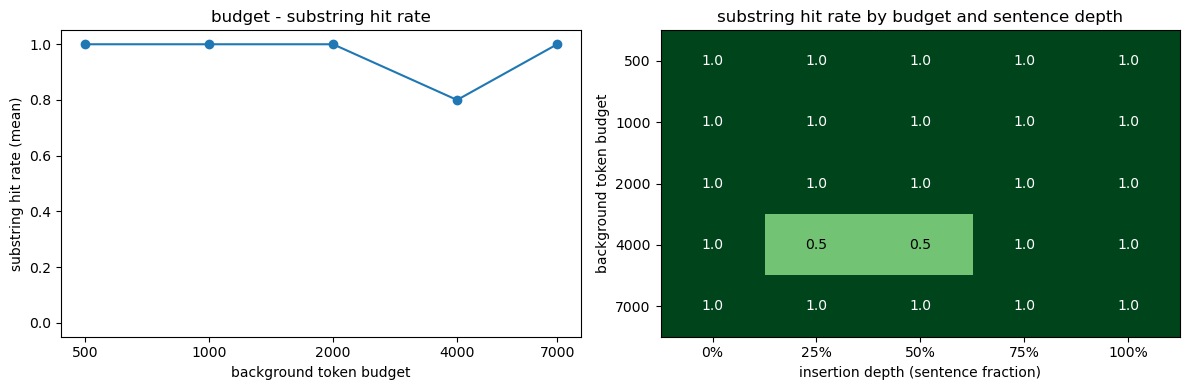

L=  500: 평균 substring 번호 포함률 1.00
L=1,000: 평균 substring 번호 포함률 1.00
L=2,000: 평균 substring 번호 포함률 1.00
L=4,000: 평균 substring 번호 포함률 0.80
L=7,000: 평균 substring 번호 포함률 1.00


In [9]:
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["axes.unicode_minus"] = False

acc = [np.mean([grid[(L, d)] for d in DEPTHS]) for L in LENGTHS]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(LENGTHS, acc, "o-")
ax1.set_xscale("log"); ax1.minorticks_off(); ax1.set_xticks(LENGTHS); ax1.set_xticklabels([str(L) for L in LENGTHS])
ax1.set_ylim(-0.05, 1.05); ax1.set_xlabel("background token budget"); ax1.set_ylabel("substring hit rate (mean)")
ax1.set_title("budget - substring hit rate")
M = np.array([[grid[(L, d)] for d in DEPTHS] for L in LENGTHS])
im = ax2.imshow(M, vmin=0, vmax=1, cmap="Greens", aspect="auto")
ax2.set_xticks(range(len(DEPTHS))); ax2.set_xticklabels([f"{d:.0%}" for d in DEPTHS])
ax2.set_yticks(range(len(LENGTHS))); ax2.set_yticklabels([str(L) for L in LENGTHS])
ax2.set_xlabel("insertion depth (sentence fraction)"); ax2.set_ylabel("background token budget")
for i in range(len(LENGTHS)):
    for j in range(len(DEPTHS)):
        ax2.text(j, i, f"{M[i, j]:.1f}", ha="center", va="center", color="white" if M[i, j] > 0.6 else "black")
ax2.set_title("substring hit rate by budget and sentence depth")
plt.tight_layout(); plt.show()
for L, a in zip(LENGTHS, acc):
    print(f"L={L:>5,}: 평균 substring 번호 포함률 {a:.2f}")

## 3. 같은 모델, 다른 채점 - 답의 첫머리를 빼면

지금까지는 프롬프트 끝에 답의 첫머리("{안내센터} 안내센터의 오늘 임시 출입 번호는")를 미리 적어 두고 6토큰만 생성했다. 이번에는 첫머리를 빼고 `답:`에서 끝낸다. 생성 길이는 8토큰과 24토큰 두 가지로 잰다. 문서와 숨긴 문장, 모델은 그대로다.

결과를 보기 전에 예측해 보자. 모델이 번호를 "아는지"는 바뀌지 않았다. 그런데 회수율도 그대로일까?

기존 프록시와 strict 번호 일치를 함께 출력. 여러 숫자나 숫자 경계 오류가 없는지는 strict로 비교하고, 부정·인용·의미 오류는 별도 사람 확인.


In [10]:
L_fmt = 500
print("[답 첫머리 없음, 8토큰 생성]")
g8 = run_grid([L_fmt], answer_prefix=False, max_new_tokens=8, show_miss=False)
print("\n[답 첫머리 없음, 24토큰 생성]")
g24 = run_grid([L_fmt], answer_prefix=False, max_new_tokens=24, show_miss=False)
print("\n깊이 50% 애월의 답 비교")
for prefix, n_new in [(True, 6), (False, 8), (False, 24)]:
    ans, _ = ask(build_prompt(L_fmt, 0.5, "애월", answer_prefix=prefix), n_new)
    print(f"  첫머리 {'있음' if prefix else '없음'}, {n_new:>2}토큰: {ans.strip()!r}")

[답 첫머리 없음, 8토큰 생성]


  위치 애월: 본문 실제 474토큰, 삽입 후 문서 704토큰, 정답 첫 출현 token index=0, 실제 token 깊이=0.0%, substring=0, strict=0


  위치 표선: 본문 실제 474토큰, 삽입 후 문서 705토큰, 정답 첫 출현 token index=0, 실제 token 깊이=0.0%, substring=0, strict=0


  위치 애월: 본문 실제 474토큰, 삽입 후 문서 705토큰, 정답 첫 출현 token index=137, 실제 token 깊이=19.4%, substring=0, strict=0


  위치 표선: 본문 실제 474토큰, 삽입 후 문서 705토큰, 정답 첫 출현 token index=137, 실제 token 깊이=19.4%, substring=0, strict=0


...

  위치 애월: 본문 실제 474토큰, 삽입 후 문서 705토큰, 정답 첫 출현 token index=681, 실제 token 깊이=96.6%, substring=1, strict=1


  위치 표선: 본문 실제 474토큰, 삽입 후 문서 705토큰, 정답 첫 출현 token index=682, 실제 token 깊이=96.7%, substring=1, strict=1
L 예산=  500 (마지막 입력 746토큰, 92초) | substring   0%:1.0   25%:1.0   50%:1.0   75%:1.0  100%:1.0
  문장 위치 비율별 strict 번호 일치 |   0%:1.0   25%:1.0   50%:1.0   75%:1.0  100%:1.0

깊이 50% 애월의 답 비교


  첫머리 있음,  6토큰: '7468이다'


  첫머리 없음,  8토큰: '애월 안내센터의 오늘'


  첫머리 없음, 24토큰: '애월 안내센터의 오늘 임시 출입 번호는 7468이다.'


## 4. 확인 질문

1. 1-3에서 KV 캐시가 가중치와 같아지는 길이는 몇 토큰이었나요? 32,768토큰이면 가중치의 몇 배인가요?
2. 1-4에서 최대 위치 안에서 한 바퀴도 못 도는 차원 쌍은 몇 개였나요? 학습 길이를 넘는 위치에서 이 쌍들에 무슨 일이 생기나요?
3. 1-5에서 입력이 2배가 될 때 프리필 시간은 몇 배가 되었나요? 2,000토큰 입력 뒤 디코딩 토큰당 시간은 프리필 시간의 몇 분의 1이었나요? 짧은 답을 받을 때 기다리는 시간의 대부분은 어느 단계인가요?
4. 2에서 길이를 늘렸을 때 substring 번호 포함률은 어떻게 바뀌었나요? 떨어졌다면 어느 깊이에서 먼저 떨어졌나요? 놓친 답은 어떤 번호였나요(다른 안내센터의 번호인가, 없는 번호인가)?
5. 3에서 답의 첫머리를 빼고 8토큰만 생성했을 때 substring 번호 포함률은 얼마였나요? 24토큰에서는요? 정답 번호가 출력됐는지와 substring 번호 포함률 숫자는 어떤 관계인가요?
6. 이 실험에서 substring 번호 포함률이 1.0이라면 "모델이 문서 전체를 이해했다"고 말할 수 있나요? 이 측정이 말해 주는 것과 말해 주지 않는 것을 한 문장씩 써 보세요.

7. substring과 strict 지표가 달라진 응답이 있었나요? 실제 본문 토큰 수·정답 토큰 깊이와 L 예산·문장 위치 비율은 얼마나 달랐나요? strict도 문장 의미를 판정하지 못하는 예를 하나 쓰세요.

답은 아래 셀에 글로 적으면 됩니다. 코드가 아니어도 됩니다.


**1. KV 캐시와 가중치 (1-3)**

- 토큰당 KV 캐시 = 2 × 28층 × KV 헤드 8 × 헤드 차원 128 × 2바이트 = 114,688바이트(112 KiB)
- 가중치(bf16)는 1.11 GiB라서 약 10,394토큰이면 KV 캐시가 가중치와 같아짐
- 32,768토큰이면 KV 캐시 3.50 GiB = 가중치의 3.15배
- KV 헤드를 쿼리 헤드 수(16)만큼 둔 MHA였다면 토큰당 224 KiB로 2배. GQA 덕분에 반으로 줄어든 것

**2. RoPE 주기 (1-4)**

- 차원 쌍 64개 중 24개가 최대 위치 32,768 안에서 한 바퀴도 못 돎. 가장 느린 쌍은 32,768까지 가도 2.3도만 돎
- 이 쌍들은 학습 때 아주 좁은 각도 범위만 봤기 때문에, 학습 길이를 넘는 위치에서는 한 번도 본 적 없는 각도가 나옴. 그러면 모델이 위치 관계를 제대로 해석 못 해서 성능이 무너질 수 있음
- 그래서 위치 보간(위치를 m_l/m 배로 줄임)이나 기저 늘리기(b를 λ배)로 학습 때 본 각도 범위 안에 넣는 방법을 씀. 예: 기저를 4.089배 하면 가장 빠른 쌍 주기는 6.28로 그대로이고 가장 느린 쌍만 4배 느려짐

**3. 프리필과 디코딩 시간 (1-5)**

- 입력이 2배가 될 때 프리필 시간
  - 250 → 500: 1.23초 → 2.68초 (2.2배)
  - 500 → 1000: 2.68초 → 5.90초 (2.2배)
  - 1000 → 2000: 5.90초 → 16.08초 (2.7배)
- 길이가 길수록 2배보다 더 많이 늘어남. 어텐션 계산이 길이의 제곱으로 늘기 때문인 것 같음
- 2,000토큰 입력 뒤 디코딩은 토큰당 약 0.245초. 프리필 16.08초의 약 1/66
- 첫 토큰까지 16.23초, 20토큰 생성까지 20.88초라서 짧은 답을 받을 때 기다리는 시간의 대부분(약 78%)은 프리필 단계임

**4. 길이를 늘렸을 때 (2절, `LENGTHS = [500, 1000, 2000, 4000, 7000]`)**

- 평균 substring 번호 포함률
  - L=500, 1000, 2000: 모두 1.00
  - L=4000: 0.80
  - L=7000: 1.00
- 4000에서 깊이 25%와 50%만 0.5로 떨어짐. 맨 앞(0%)과 뒤쪽(75%, 100%)은 1.0이라 중간 부분에서 먼저 떨어짐
- 놓친 답은 둘 다 표선을 물었을 때였음. 없는 번호가 아니라 다른 안내센터의 번호였음
  - 25%: 3471(한림 번호)
  - 50%: 7468(애월 번호)
  - 비슷한 문장 여러 개 중에서 엉뚱한 것을 옮긴 것
- 7000에서는 다시 전부 맞음. 깊이마다 안내센터 2개만 물어서 칸 하나가 0.5씩 움직이니까, 4000의 하락이 길이 때문인지 우연인지는 이 실험만으로는 단정 못 함
- 시간은 길이보다 훨씬 빠르게 늘어남. 행별 시간: 54초 → 101초 → 234초 → 805초 → 1,992초. 4000 → 7000은 길이 1.75배인데 시간은 약 2.5배

**5. 답의 첫머리를 뺐을 때 (3절, L=500)**

- 8토큰 생성: substring 번호 포함률 0.0(10건 모두 0)
- 24토큰 생성: 1.0(10건 모두 맞음)
- 깊이 50% 애월 예시
  - 8토큰: "애월 안내센터의 오늘"
  - 24토큰: "애월 안내센터의 오늘 임시 출입 번호는 7468이다."
- 모델이 질문을 되풀이하느라 8토큰 안에 번호까지 도달하지 못한 것. 모델이 번호를 몰라서 0이 된 게 아님
- 즉 substring 포함률은 "모델이 번호를 아는가"가 아니라 "정해진 길이 안에 번호를 출력했는가"를 잼. 같은 모델이라도 프롬프트 형식과 생성 길이에 따라 0.0이 되기도 하고 1.0이 되기도 함

**6. 포함률 1.0이면 문서 전체를 이해했다고 할 수 있나**

- 말할 수 없음
- 이 측정이 말해 주는 것: 질문과 글자 그대로 겹치는 문장을 긴 문서 속에서 찾아 그 번호를 옮겨 쓸 수 있는지
- 이 측정이 말해 주지 않는 것: 문서의 다른 내용을 이해했는지, 여러 문장을 종합해서 판단할 수 있는지(5주차의 "지표가 측정하지 못하는 것")

**7. substring vs strict, 메타데이터**

- 이번 실행에서는 substring과 strict가 달라진 응답이 없었음. 맞은 답은 전부 "7468이다"처럼 숫자 하나만 나왔고, 틀린 답은 둘 다 0이었음
- L 예산과 실제 본문 토큰 수 차이
  - 예산 500 → 실제 본문 474토큰, 숨긴 문장 10개를 넣으면 704~705토큰
  - 예산 4000 → 3,969토큰 → 4,199~4,200토큰
  - 예산 7000 → 6,988토큰 → 7,218~7,219토큰
  - 예산은 상한이라 본문은 조금 작고, 숨긴 문장 때문에 매번 약 230토큰이 더해짐
- 문장 위치 비율과 실제 토큰 깊이 차이
  - 25% → 19.4%(L=500), 27.3%, 28.5%, 24.9%, 24.6%
  - 50% → 40.3%(L=500), 55.1%, 51.3%, 45.9%, 52.6%
  - 100% → 96.6~99.7%(뒤에 질문용 문장이 아니라 다른 숨긴 문장이 붙어서 100%가 아님)
  - 문장 길이가 제각각이라 문장 개수 비율과 토큰 위치가 많게는 10%p 가까이 차이 남
- strict도 의미를 판정 못 하는 예: "7468은 아니다"처럼 정답 번호를 부정하는 답도 숫자열이 7468 하나뿐이라 strict에서는 정답으로 통과됨(노트북 assert에도 있음)


## 5. 제출

1. 상단 메뉴 **파일 > .ipynb 다운로드** 로 이 노트북을 내려받습니다
2. [저장소](https://github.com/halla-ai/deepnlp-2026)의 `assignments/week-07/<내 학번>/` 에 업로드합니다
3. Pull Request를 엽니다

자세한 방법은 강의 사이트의 **과제 제출** 문서에 있습니다.

---

**막혔나요?** 오류 메시지의 마지막 줄을 먼저 읽어 보세요. 그래도 안 되면 AI Professor 튜터에게 묻고, 그래도 막히면 저장소 Issues에 남기세요.